# Notebook 04: Exploratory Data Analysis

**Project:** Credit Decision Assistant

## What this notebook is for

Notebook 03 settled which 62 features the model may use. Before building anything, this notebook gets to know them. It asks five questions:

1. **Which features actually separate borrowers who default from those who don't**, and by how much?
2. **What shape does each relationship have?** Steady (more debt, more risk), curved, or flat?
3. **Which features are near-duplicates of each other?**
4. **Are there fake or extreme values** that need handling?
5. **Is each feature's relationship with default stable from year to year?**

**Training set only.** Everything here shapes later decisions: which features to keep, how to treat missing values, how to group categories. If the validation or test loans were looked at while making those decisions, they would no longer be an independent check. So they aren't even loaded.

## A few terms used in this notebook

| Term | What it means here |
|---|---|
| **AUROC** | Pick one borrower who defaulted and one who didn't, at random. AUROC is the chance that a feature ranks the defaulter as riskier. 0.5 is a coin flip, 1.0 is perfect separation. |
| **Gini** | The same thing rescaled to run from 0 (useless) to 1 (perfect): Gini = \|2 x AUROC - 1\|. For a single feature in lending data, above 0.10 is meaningful and above 0.20 is strong. |
| **Decile** | One of ten equal-sized groups, made by sorting borrowers on a feature. |
| **Rank correlation (Spearman)** | How similarly two features order the borrowers, from -1 to +1. Near +1 or -1 means one feature is largely redundant given the other. |
| **Placeholder value** | A code such as 9,999,999 used to mean "unknown" rather than a real amount. |
| **Monotone relationship** | One that only goes one way: as the feature rises, risk only rises (or only falls). |

## What this notebook produces

- `outputs/tables/04_numeric_feature_overview.csv`: summary statistics and predictive strength for every numeric feature.
- `outputs/tables/04_highly_correlated_pairs.csv`: pairs of features that carry almost the same information.
- `outputs/figures/04_default_rate_by_decile.png`: the shape of the 12 strongest relationships.

No data is changed here. The decisions this notebook leads to are applied in Notebook 05.

## Setup

Only the training set is loaded: 791,027 loans issued from 2013 to 2015, with a 3.11% default rate. The feature lists and target name come from the config file written by the earlier notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import roc_auc_score      # used to measure each feature's predictive strength

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT  = Path.cwd().parent
INTERIM_DIR   = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR       = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR     = PROJECT_ROOT / "outputs" / "tables"

with open(INTERIM_DIR / "audit_config.json") as f:
    config = json.load(f)

NUMERIC     = config["features"]["numeric"]
CATEGORICAL = config["features"]["categorical"]
TARGET      = config["target"]["name"]

# Training set only: validation and test stay unseen while we make decisions
train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
print(f"Train: {len(train):,} loans | default rate {train[TARGET].mean():.2%} | "
      f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features")

Train: 791,027 loans | default rate 3.11% | 59 numeric + 3 categorical features


## Step 1: How strongly does each numeric feature separate defaulters?

To compare 59 numeric features on equal terms, each one is asked the same question: *if borrowers were sorted by this feature alone, how well would that sort put defaulters above non-defaulters?*

That's measured with the **AUROC**:

$$\text{AUROC} = P(x_{\text{defaulter}} > x_{\text{non-defaulter}}) + \tfrac{1}{2} P(\text{tie})$$

A value below 0.5 means the feature works in reverse (higher values mean safer). To compare strength regardless of direction, the table uses the **Gini**, $|2 \times \text{AUROC} - 1|$, and a separate column says which direction it works in.

AUROC only depends on the **order** of values, not their size, so it isn't thrown off by extreme values or skewed features like income. For features with missing values, it's calculated on the loans where the value is present. Whether "missing" itself carries a signal is looked at separately.

**Result:**

**1. The strongest signal is "credit hunger", not past mistakes.**

| Feature | Gini | What it measures |
|---|---|---|
| `acc_open_past_24mths` | 0.188 | Accounts opened in the last 2 years |
| `num_tl_op_past_12m` | 0.182 | Accounts opened in the last 12 months |
| `fico_range_low` | 0.162 | Credit score (higher = safer) |
| `mo_sin_rcnt_tl` | 0.147 | Months since the most recent account was opened (higher = safer) |
| `dti` | 0.139 | Debt payments as a share of income |
| `mths_since_recent_inq`, `inq_last_6mths` | 0.135 | Recent credit checks by lenders |

Four of the top seven measure how actively someone has been looking for new credit recently. Opening several accounts and getting lots of credit checks in a short time often means someone is stretched for money and borrowing to cover other borrowing. Among approved borrowers, that's a stronger warning sign than anything in their past.

**2. Past mistakes barely register.** Late payments (`delinq_2yrs`, 0.005), public records (`pub_rec`, 0.010), bankruptcies (0.008) and collections (0.004) are at the very bottom. This matches the selection bias found in Notebook 03: Lending Club's screening had already filtered on these, so among the approved borrowers they no longer separate anyone.

**3. Loan amount on its own says almost nothing (Gini 0.005).** A $20,000 loan means something very different to someone earning $40,000 than to someone earning $200,000. Loan amount *relative to income* should carry much more signal, and is one of the features to build in Notebook 05.

**4. Lending Club's own rules show up in the data:** the lowest credit scores are 660 (its minimum), debt-to-income stops at exactly 40 (its maximum for individual applications) and loan amounts stop at $35,000 (its cap in 2013 to 2015).

**5. Something looks wrong:** `tot_hi_cred_lim` and `total_rev_hi_lim` both have a maximum of exactly **9,999,999**, while 99% of values sit below about 750,000 and 150,000. That looks like a placeholder, checked in Step 4.

In [2]:
y = train[TARGET].values                     # 1 = defaulted within 12 months, 0 = did not
rows = []
for c in NUMERIC:
    x = train[c]
    present = x.notna().values
    rows.append({
        "feature":   c,
        "missing":   x.isna().mean(),
        "n_unique":  x.nunique(),
        "p1":        x.quantile(0.01),
        "median":    x.median(),
        "p99":       x.quantile(0.99),
        "max":       x.max(),
        # Single-feature AUROC, using the loans where the value is present
        "auroc":     roc_auc_score(y[present], x.values[present]),
    })
overview = pd.DataFrame(rows).set_index("feature")
overview["gini"]      = (2 * overview["auroc"] - 1).abs()         # strength, ignoring direction
overview["direction"] = np.where(overview["auroc"] > 0.5, "higher = riskier", "higher = safer")
overview = overview.sort_values("gini", ascending=False)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
overview.to_csv(TABLE_DIR / "04_numeric_feature_overview.csv")

display(overview.style.format({"missing": "{:.1%}", "auroc": "{:.3f}", "gini": "{:.3f}",
                               "n_unique": "{:,}", "p1": "{:,.1f}", "median": "{:,.1f}",
                               "p99": "{:,.1f}", "max": "{:,.1f}"})
               .bar(subset=["gini"], color="#9AA5B1"))

,missing,n_unique,p1,median,p99,max,auroc,gini,direction
feature,,,,,,,,,
acc_open_past_24mths,0.0%,48,0.0,4.0,14.0,64.0,0.594,0.188,higher = riskier
num_tl_op_past_12m,0.0%,28,0.0,2.0,8.0,30.0,0.591,0.182,higher = riskier
fico_range_low,0.0%,38,660.0,685.0,795.0,845.0,0.419,0.162,higher = safer
mo_sin_rcnt_tl,0.0%,173,0.0,6.0,46.0,263.0,0.427,0.147,higher = safer
dti,0.0%,"4,000",2.3,18.0,37.7,40.0,0.570,0.139,higher = riskier
mths_since_recent_inq,10.2%,26,0.0,5.0,23.0,25.0,0.432,0.135,higher = safer
inq_last_6mths,0.0%,7,0.0,0.0,4.0,6.0,0.567,0.135,higher = riskier
mo_sin_old_rev_tl_op,0.0%,729,34.0,168.0,472.0,851.0,0.437,0.125,higher = safer
credit_history_m,0.0%,696,49.0,181.0,478.0,852.0,0.443,0.115,higher = safer


## Step 2: The categorical features (and loan term)

For a category, "sorting by the feature" means ordering the categories by their default rate. Each table shows how many loans fall in each category, their default rate, and the Gini of ranking borrowers this way. The Gini is slightly flattering, since the default rates are measured on the same loans they're scored on, but with hundreds of thousands of loans in most categories the effect is negligible. It only matters for tiny categories, which is why their size is shown.

**Result:**

**Home ownership (Gini 0.103):** mortgage holders are safest (2.53%), then people who own outright (3.36%), then renters (3.79%). A mortgage means a lender has already checked this person thoroughly, and they usually have stable housing and a longer track record. "OTHER" has only 3 loans in the training years, so it will be folded into the closest group.

**Verification status (Gini 0.117), the counter-intuitive one:**

| | Default rate |
|---|---|
| Verified | 3.85% |
| Source Verified | 3.18% |
| Not Verified | 2.16% |

Borrowers whose income Lending Club *checked* default almost twice as often as those it didn't. That makes sense once you ask *why* Lending Club checked: it didn't verify everyone, only applicants who looked riskier. So "Verified" really means "Lending Club was suspicious enough to ask for proof". The column records Lending Club's own risk judgement, much like the grade and interest rate excluded in Notebook 01. In this project, asking for income verification is one of the conditions the decision engine sets for riskier applicants, so using it as an input to the risk model would make the system feed back on itself. **Recommendation: exclude it from the risk model** and keep it as a decision-engine output. The final call is recorded in Notebook 05.

**Purpose (Gini 0.105):** the two big groups are on the safer side: debt consolidation (60% of loans, 3.25%) and credit card refinancing (24%, 2.21%, the safest). The riskiest purposes are small ones that often come with a disrupted life or an uncertain income: moving (6.27%), small business (6.24%) and medical (5.18%). Very small categories, such as educational with a single loan, will be grouped with similar purposes.

**Term (Gini 0.090):** 60-month loans default at 3.99% against 2.72% for 36-month loans, about 1.5 times as often. With only two possible values a feature can't rank borrowers finely, so its Gini understates how useful it is.

In [3]:
def category_table(col):
    """Default rate and size for each category, riskiest first."""
    t = (train.groupby(col, observed=True)[TARGET]
              .agg(n_loans="size", default_rate="mean")
              .sort_values("default_rate", ascending=False))
    t["share_of_loans"] = t["n_loans"] / len(train)
    # Gini of ranking borrowers by their category's default rate
    rate = train[col].map(t["default_rate"])
    gini = abs(2 * roc_auc_score(train[TARGET], rate) - 1)
    return t, gini

for col in CATEGORICAL + ["term_m"]:
    t, gini = category_table(col)
    print(f"\n{col}  (Gini {gini:.3f}, {len(t)} categories)")
    display(t.style.format({"n_loans": "{:,}", "default_rate": "{:.2%}", "share_of_loans": "{:.1%}"}))


home_ownership  (Gini 0.103, 4 categories)


,n_loans,default_rate,share_of_loans
home_ownership,,,
RENT,"311,704",3.79%,39.4%
OWN,"79,989",3.36%,10.1%
MORTGAGE,"399,331",2.53%,50.5%
OTHER,3,0.00%,0.0%



verification_status  (Gini 0.117, 3 categories)


,n_loans,default_rate,share_of_loans
verification_status,,,
Verified,"256,127",3.85%,32.4%
Source Verified,"314,233",3.18%,39.7%
Not Verified,"220,667",2.16%,27.9%



purpose  (Gini 0.105, 14 categories)


,n_loans,default_rate,share_of_loans
purpose,,,
moving,"4,386",6.27%,0.6%
small_business,"6,998",6.24%,0.9%
renewable_energy,398,5.78%,0.1%
medical,"7,156",5.18%,0.9%
wedding,607,4.45%,0.1%
house,"2,863",4.40%,0.4%
other,"35,391",4.23%,4.5%
vacation,"3,991",4.18%,0.5%
major_purchase,"13,604",3.91%,1.7%



term_m  (Gini 0.090, 2 categories)


,n_loans,default_rate,share_of_loans
term_m,,,
60,"245,101",3.99%,31.0%
36,"545,926",2.72%,69.0%


## Step 3: What shape does each relationship have?

The Gini gives one number per feature, but not the shape. Here the training loans are split into 10 equal groups by each feature, and the default rate is plotted for each group. When many loans share the same value (lots of zeros, for example), some groups get merged, so a few charts have fewer than 10 points. The dashed line is the overall default rate. For features with missing values, a blue dotted line shows the default rate of the loans where the value is missing.

**Result:**

**1. All 12 relationships are steady and one-directional, with no U-shapes.** Borrowers in the top group for accounts opened in the last 2 years default at 5.3%, against 1.75% in the bottom group. Credit score runs from 4.2% at the bottom to 1.6% at the top, with most of the drop happening above about 695. Income, credit limits, length of credit history and time since the last new account all get steadily safer as they rise. This suits a scorecard, where each feature's groups should step up or down in order, and it means gradient boosting can be told to keep these relationships one-directional (a *monotone constraint*), which makes it more stable and easier to explain.

**2. Two relationships aren't straight lines.**
- **Debt-to-income bends upward.** It stays at about 2.4% up to a ratio of about 13%, then climbs faster and faster to 4.8% in the top group (30% to 40%). A little debt is normal; a lot becomes dangerous quickly.
- **Total credit limit is flat, then falls.** It stays around 3.7% for the bottom four groups (up to about $78,000), then drops steadily to 2.0%.

Binning (in the scorecard) and trees (in gradient boosting) both capture shapes like these naturally.

**3. Missing values mean different things for different features.**
- **`mths_since_recent_inq` missing: 1.9%, the safest group of all**, lower even than the top group. Missing means no lender has checked this person's credit recently, so they aren't out shopping for credit. This confirms the "never happened" reading from Notebook 03.
- **`bc_open_to_buy` missing: 4.1%, about as risky as the lowest group.** This measures unused credit card limit, so missing most likely means no credit card at all, which usually points to a thin credit history.

These two cases show why missing values should never be filled in blindly with an average: one would be pulled from the safest group to the middle, the other from the riskiest group to the middle.

**4. Two charts look almost identical:** `credit_history_m` and `mo_sin_old_rev_tl_op` (age of the oldest credit card). Step 4 measures this kind of overlap across all features.

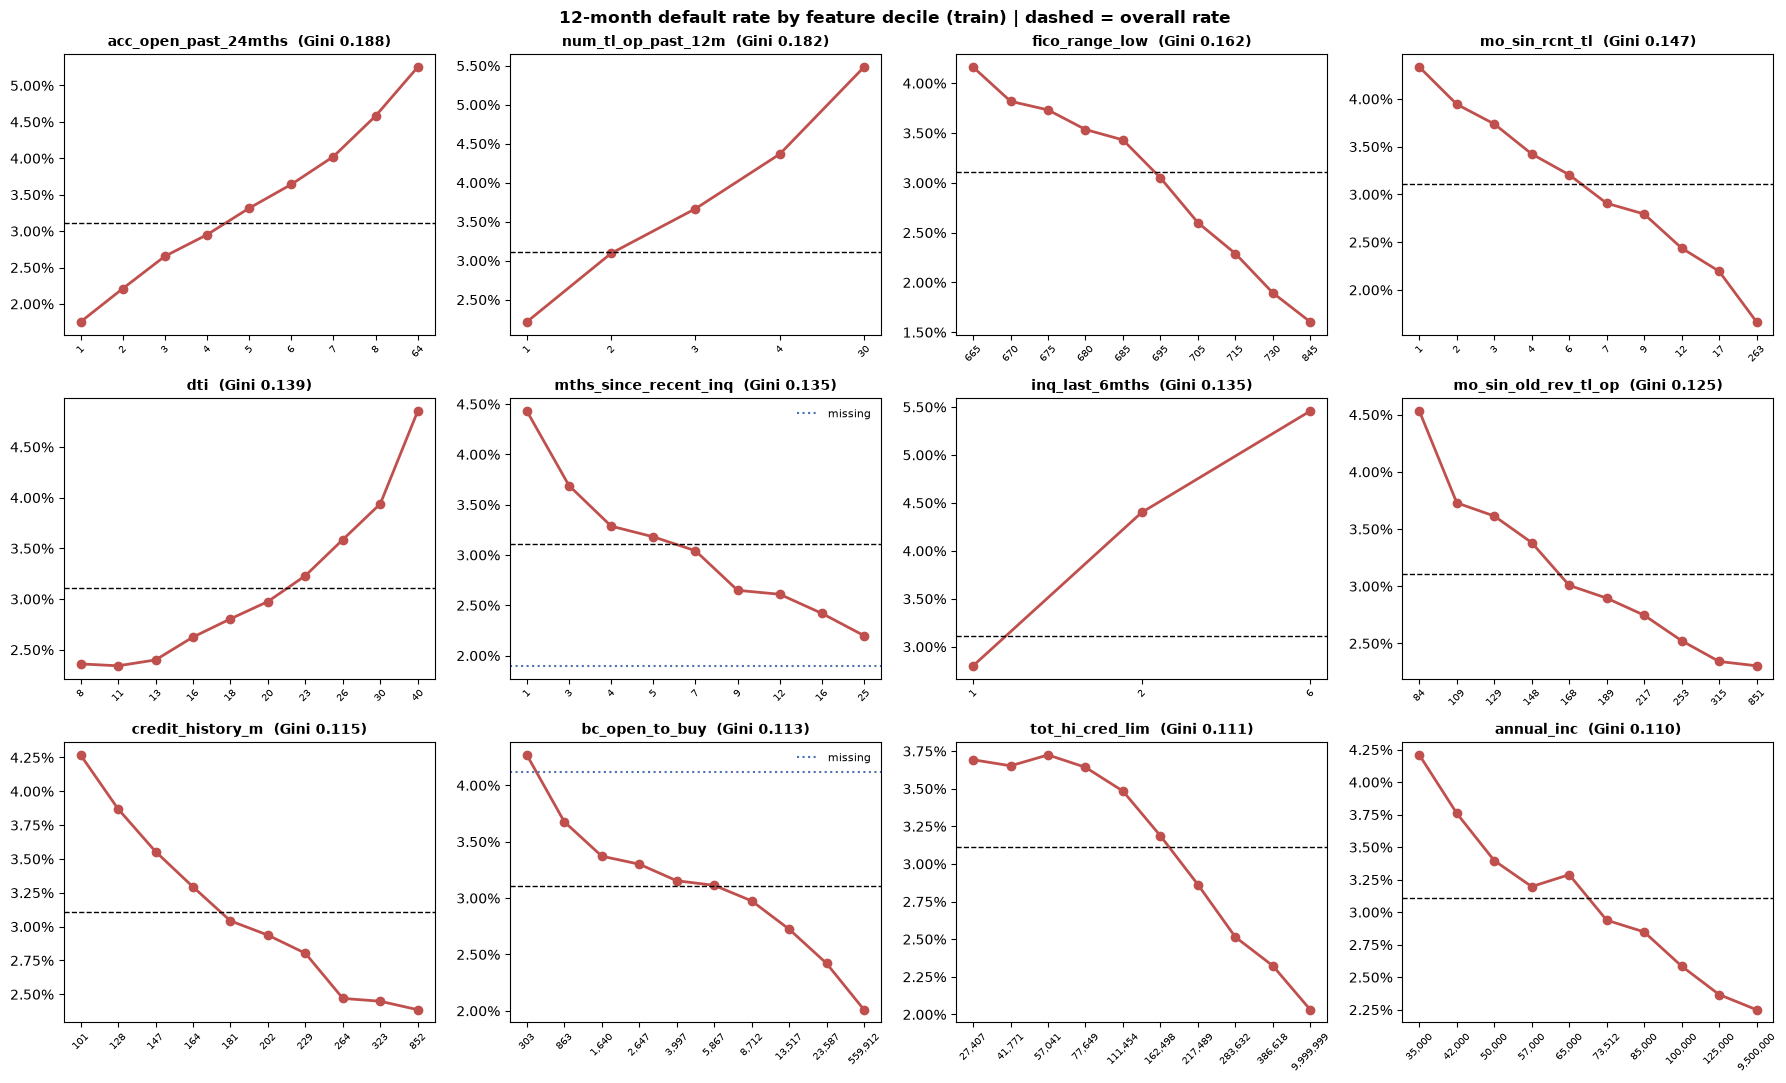

In [4]:
TOP = overview.index[:12].tolist()          # the 12 strongest numeric features

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), TOP):
    x = train[c]
    present = x.notna()
    # duplicates="drop" merges deciles when many loans share the same value (e.g. lots of zeros)
    bins = pd.qcut(x[present], q=10, duplicates="drop")
    rate = train.loc[present, TARGET].groupby(bins, observed=True).mean()
    labels = [f"{iv.right:,.0f}" for iv in rate.index]       # upper edge of each group
    ax.plot(range(len(rate)), rate.values, marker="o", lw=2, color="#C0504D")
    ax.axhline(train[TARGET].mean(), color="black", ls="--", lw=1)   # overall default rate
    if x.isna().any():
        ax.axhline(train.loc[~present, TARGET].mean(), color="#4C72B0", ls=":", lw=1.5,
                   label="missing")
        ax.legend(frameon=False, fontsize=8)
    ax.set_xticks(range(len(rate)), labels, rotation=45, fontsize=7)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(f"{c}  (Gini {overview.loc[c, 'gini']:.3f})", fontsize=10, fontweight="bold")
fig.suptitle("12-month default rate by feature decile (train) | dashed = overall rate",
             fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_default_rate_by_decile.png", dpi=150)
plt.show()

## Step 4: Placeholder values and near-duplicate features

**Placeholders.** Every numeric feature is scanned for the usual "unknown" codes (999, 9,999, 99,999, 999,999 and 9,999,999). The check matches exact values, so it also catches real amounts that happen to be, say, $999. The feature's 99th percentile is shown alongside: a placeholder sits far above normal values, a real value doesn't.

**Near-duplicates.** For every pair of numeric features, the rank correlation (Spearman) measures how similarly they order the borrowers. Like AUROC, it only uses order, so skewed features and extreme values don't distort it, and it catches any steady relationship, not just straight lines. Pairs at 0.80 or above are listed with each feature's Gini, because when one of a pair is dropped later, the stronger one is usually kept.

**Result: placeholders.**
- **9,999,999 in `tot_hi_cred_lim` (6 loans) and `total_rev_hi_lim` (3 loans)** sits 13 and 65 times above their 99th percentiles. Nobody has a $10 million credit limit recorded as all nines. These are placeholders and will be treated as missing.
- **The 999s and 9,999s** in balance and limit columns sit well inside the normal range, and the counts are tiny (a few dozen out of 791,027). A revolving balance of $9,999 is entirely ordinary, so these are left alone.
- **One income of $999,999** is suspicious but possible. Extreme values will be capped at a high percentile of the training data in Notebook 05, which handles it without guessing.

**Result: near-duplicates.** 19 pairs reach 0.80, and they form a handful of families:

| Family | Features | Rank correlation |
|---|---|---|
| Open accounts | `open_acc`, `num_sats`, `num_op_rev_tl` | 0.82 to 0.998 |
| Active revolving accounts | `num_actv_rev_tl`, `num_rev_tl_bal_gt_0` | 0.990 |
| Total balances and limits | `tot_cur_bal`, `tot_hi_cred_lim`, `avg_cur_bal` | 0.89 to 0.98 |
| Credit card limits | `total_rev_hi_lim`, `total_bc_limit` | 0.86 |
| Age of credit history | `credit_history_m`, `mo_sin_old_rev_tl_op` | 0.90 |
| Card usage | `revol_util`, `bc_util`, `percent_bc_gt_75` | 0.82 to 0.86 |
| Past late payments | the "months since..." columns, `delinq_2yrs` | 0.83 to 0.89 |
| Public records | `pub_rec`, `pub_rec_bankruptcies` | 0.82 |
| Credit cards held | `num_bc_tl`, `num_rev_accts`, `num_actv_bc_tl`, `num_bc_sats` | 0.83 to 0.85 |

`open_acc` and `num_sats` agree at 0.998: they are practically the same column, since nearly every open account is in good standing ("satisfactory"). On the other hand, the two strongest features, accounts opened in the last 12 and 24 months, did *not* reach 0.80. They overlap, but each carries something the other doesn't.

**Why this matters:** a scorecard (logistic regression) struggles when two features say the same thing. It can't tell which one deserves the credit, so their weights become unstable and can even flip sign. So Notebook 05 will keep one feature per family for the scorecard. Gradient boosting copes with duplicates and can keep more of them. Nothing is removed in this notebook.

In [5]:
# Part 1: placeholder values (codes like 9,999,999 that stand for "unknown", not real amounts)
SENTINELS = [999, 9_999, 99_999, 999_999, 9_999_999]
hits = []
for c in NUMERIC:
    for s in SENTINELS:
        n = (train[c] == s).sum()
        if n > 0:
            hits.append({"feature": c, "value": s, "n_loans": n,
                         "p99_of_feature": train[c].quantile(0.99)})
print("Exact placeholder-like values found in train:")
display(pd.DataFrame(hits).sort_values("n_loans", ascending=False) if hits else "none")

# Part 2: pairs of features that rank borrowers almost identically
print("\nComputing rank correlations between all numeric features (about a minute)...")
corr = train[NUMERIC].corr(method="spearman")

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))     # each pair once
             .stack().rename("spearman").reset_index()
             .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs = pairs[pairs["spearman"].abs() >= 0.80].sort_values("spearman", key=abs, ascending=False)
pairs["gini_a"] = pairs["feature_a"].map(overview["gini"])
pairs["gini_b"] = pairs["feature_b"].map(overview["gini"])
print(f"Pairs with |rank correlation| >= 0.80: {len(pairs)}")
display(pairs.style.format({"spearman": "{:.3f}", "gini_a": "{:.3f}", "gini_b": "{:.3f}"}))
pairs.to_csv(TABLE_DIR / "04_highly_correlated_pairs.csv", index=False)   # used in Notebook 05

Exact placeholder-like values found in train:


,feature,value,n_loans,p99_of_feature
12,bc_open_to_buy,999,118,"68,366.5625"
10,avg_cur_bal,999,58,"71,615.5781"
3,revol_bal,9999,46,"94,874.1800"
19,total_il_high_credit_limit,9999,33,"199,914.6600"
13,bc_open_to_buy,9999,27,"68,366.5625"
4,tot_coll_amt,999,24,"4,747.0000"
2,revol_bal,999,23,"94,874.1800"
11,avg_cur_bal,9999,22,"71,615.5781"
17,total_bal_ex_mort,9999,20,"231,636.4400"
6,tot_cur_bal,9999,16,"659,984.1000"



Computing rank correlations between all numeric features (about a minute)...
Pairs with |rank correlation| >= 0.80: 19


,feature_a,feature_b,spearman,gini_a,gini_b
575,open_acc,num_sats,0.998,0.005,0.004
2226,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.990,0.009,0.009
1115,tot_cur_bal,tot_hi_cred_lim,0.977,0.089,0.111
1083,tot_cur_bal,avg_cur_bal,0.929,0.089,0.093
1651,mo_sin_old_rev_tl_op,credit_history_m,0.898,0.125,0.115
1292,avg_cur_bal,tot_hi_cred_lim,0.889,0.093,0.111
1922,mths_since_recent_bc_dlq,mths_since_recent_revol_delinq,0.886,0.019,0.012
447,mths_since_last_delinq,mths_since_recent_revol_delinq,0.872,0.018,0.012
1407,bc_util,percent_bc_gt_75,0.863,0.059,0.069
1176,total_rev_hi_lim,total_bc_limit,0.863,0.093,0.109


## Step 5: Are the relationships stable from year to year?

The training set covers loans issued in 2013, 2014 and 2015. If a feature's strength, or worse its direction, changes a lot across those years, it's less trustworthy for predicting later loans. This check uses the **signed** Gini (2 x AUROC - 1, without taking the absolute value), so a change of direction would show up as a change of sign. Red cells mean "higher is riskier", blue cells "higher is safer".

**Result:**
- **All 20 of the strongest features keep the same direction in all three years.** No sign flips.
- **Changes in strength are small**, at most 0.05 Gini between the strongest and weakest year.
- **Credit hunger got stronger:** accounts opened in the last 24 months went from 0.163 in 2013 to 0.204 in 2015, and debt-to-income rose steadily from 0.114 to 0.143.
- **Income got weaker:** from 0.140 in 2013 to 0.096 in 2015, the largest decline in the table. Worth watching, since a feature that keeps weakening may carry less signal in the later validation and test years.

Overall, the strongest relationships are stable enough to learn from 2013 to 2015 and apply to later loans.

In [6]:
TOP_STAB = overview.index[:20].tolist()       # the 20 strongest numeric features from Step 1
years = sorted(train["issue_year"].unique())

stab = pd.DataFrame(index=TOP_STAB, columns=years, dtype=float)
for yr in years:
    sub = train[train["issue_year"] == yr]
    for c in TOP_STAB:
        present = sub[c].notna()
        stab.loc[c, yr] = 2 * roc_auc_score(sub.loc[present, TARGET], sub.loc[present, c]) - 1

stab["range"] = stab[years].max(axis=1) - stab[years].min(axis=1)
stab["direction_stable"] = (np.sign(stab[years]).nunique(axis=1) == 1)
print("Signed Gini by issue year (positive = higher is riskier, negative = higher is safer):")
display(stab.style.format({y: "{:+.3f}" for y in years} | {"range": "{:.3f}"})
                  .background_gradient(subset=years, cmap="RdBu_r", vmin=-0.25, vmax=0.25))

Signed Gini by issue year (positive = higher is riskier, negative = higher is safer):


,2013,2014,2015,range,direction_stable
acc_open_past_24mths,+0.163,+0.154,+0.204,0.051,True
num_tl_op_past_12m,+0.175,+0.144,+0.195,0.051,True
fico_range_low,-0.175,-0.150,-0.162,0.024,True
mo_sin_rcnt_tl,-0.154,-0.125,-0.152,0.029,True
dti,+0.114,+0.128,+0.143,0.029,True
mths_since_recent_inq,-0.154,-0.117,-0.137,0.038,True
inq_last_6mths,+0.159,+0.119,+0.145,0.040,True
mo_sin_old_rev_tl_op,-0.117,-0.124,-0.130,0.013,True
credit_history_m,-0.104,-0.118,-0.119,0.014,True
bc_open_to_buy,-0.112,-0.123,-0.115,0.011,True


## Findings

1. **Recent credit-seeking is the strongest warning sign.** Accounts opened in the last 12 to 24 months, recent credit checks and time since the last new account dominate the ranking, ahead of credit score and debt-to-income.
2. **Past late payments, public records and bankruptcies barely separate approved borrowers**, consistent with the selection bias found in Notebook 03.
3. **Every strong numeric relationship is one-directional.** Debt-to-income bends upward sharply above about 23%, and total credit limit only starts to help above about $78,000.
4. **Missing values carry meaning.** No recent credit check (missing `mths_since_recent_inq`) is the safest group of all, while no credit card (missing `bc_open_to_buy`) behaves like the riskiest. Missing values must not be filled in with averages.
5. **Loan amount alone is almost useless**, which points to building ratios such as loan-to-income in Notebook 05.
6. **Income verification works backwards** (verified borrowers are riskier) because it reflects Lending Club's own suspicion. Recommended for exclusion from the risk model.
7. **9,999,999 is a placeholder** in two credit-limit columns and will be treated as missing. Other round values look real.
8. **19 pairs of features are near-duplicates**, forming about nine families. The scorecard will keep one feature per family.
9. **The strongest relationships are stable across 2013, 2014 and 2015**, with no change of direction. Income is the one feature that weakens noticeably over time.

**Next:** Notebook 05 turns these findings into the final feature set: new ratio features, placeholder and extreme-value handling, missing-value treatment, grouping of small categories, and binning for the scorecard.